File: waechtler_linear_regression_notebook_3.ipynb

Author: Emmett C. Waechtler

Course: ISTA 421 - Introduction to Machine Learning

Professor: Salena Torres


Preface:

I looked at the ToMCAT dataset for formulating my research question. For the ToMCAT experiment, 40 teams of three people completed simulated urban search-and-rescue missions in a Minecraft-based testbed, with physiological data (fNIRS, EEG, skin conductance, heart rate, eye tracking) recorded alongside gameplay data, demographics, and questionnaires. Teams also did short non-Minecraft tasks such as finger tapping, ping-pong, and an affective image-rating task.

Scanning through the tables, I came upon one called affective_task_event, where two columns caught my eye: arousal_score and valence_score. Arousal and valence are the two standard dimensions of affect, so the questions naturally arise: does valence change linearly with arousal? if so, how strong is this relationship? how accurately can a reaction be predicted when an arousal level is known?

Given the participants were exposed to intense simulated urban search-and-rescue situations before being tested for valence and arousal, the experiment provides an ethical way of answering the question.

Both measures are numeric, in the same table comprised of 2,373 rows.

Recall the Normal Equations to Implement Linear Regression for ToMCAT:

$$\hat{\beta}_1 = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{n}(x_i - \bar{x})^2}$$

$$\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$$

CONCEPTUAL QUESTIONS:

Question 1: Compare and Contrast RSS and RSE

RSS (Residual Sum of Squares) is the sum of the squares of the residuals, which are the
differences between the observed and predicted values in a regression model. (cite James properly).


RSS Equation:

$$\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

where $y_i$ is the observed value and $\hat{y}_i$ is the predicted value.

RSE (Residual Standard Error) is the standard deviation of the residuals, providing a measure of the average amount that the observed values deviate from the predicted values. In other words, RSE is considered a measure of the lack of fit of the model to the data. (cite James)

RSE Equation:

$$ \sqrt{\frac{RSS}{n - p - 1}} $$

where $n$ is the number of observations and $p$ is the number of predictors in the model.

Question 2: Compare and Contrast MSE and Loss Function

MSE (Mean Squared Error) is a specific type of loss function that calculates the average of the squares of the errors.

$$MSE = \frac{1}{n} \sum{i=1}^{n} (y_i - \hat{y}_i)^2$$

where $y_i$ is the observed value and $\hat{y}_i$ is the predicted value.

Loss Function is a broader concept that quantifies the difference between predicted and actual values. MSE is one example of a loss function, but there are others.

$$Loss = \sum_{i=1}^{n} (y_i - g(x_i))^2$$

where $g(x_i)$ is the prediction function. The loss function encourages $g$ to fit the data. (cite)

Question 3: What is the Importance of Linear Regression?

Linear regression is important because it provides a simple yet powerful way to model the relationship between a dependent variable and one or more independent variables.

It is widely used for prediction, inference, and understanding relationships in data.

While seemingly trivial, it forms the foundation for more complex models and statistical methods. Linear regression alone can have varying degrees of simplicity or complexity, such as regressing multiple variables or incorporating polynomial terms.

In terms of versatility, linear regression can be adapted to fit a wide range of data types and scenarios, making it a fundamentally important tool in machine learning.

Question 4: How to interpret linear regression as 'good' or 'bad'?

Linear regression has several metrics of interpretability. Examples learned in class include:

1. R-squared: Indicates the proportion of variance in the dependent variable that is explained by the independent variable(s). Higher absolute values (closer to 1 or -1) suggest a better or 'good' fit. Lower values (closer to 0) suggest a 'bad' fit.
2. Bias-variance tradeoff: A model with low bias and low variance (or bias-variance 'sweetspot') is generally considered 'good'. A model with high bias (underfitting) or high variance (overfitting) is considered 'bad'.
3. Residual analysis: Examining the residuals can provide insights into the model's fit. Randomly distributed residuals around zero suggest a 'good' fit, while patterns in the residuals is more indicative of a 'bad' fit.

Matplotlib is building the font cache; this may take a moment.


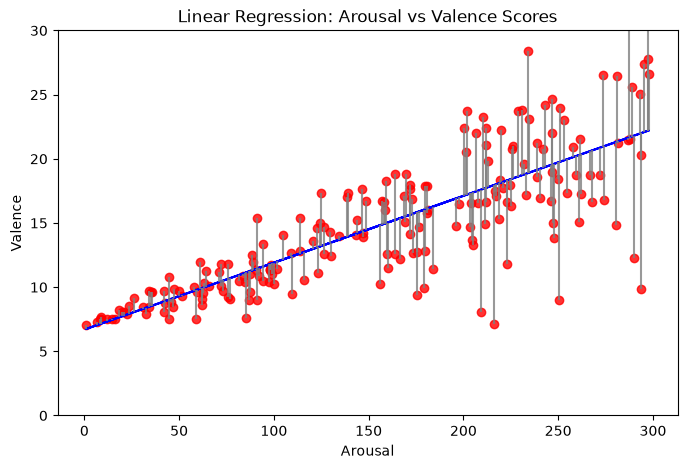

In [4]:
import matplotlib.pyplot as plt
import numpy
import pandas
from sklearn.linear_model import LinearRegression
import scipy.stats as stats

# Use variable to demonstrate that as
# n-> inf, then var-> 0
# 100 for replicating figure 3.1 from James
# 1000 and 30 for demonstrating effects of n and var

my_number = 200
my_alpha = 0.8

if my_number == 1000:
    my_alpha = 0.3

# numpy.random.seed(6)
Arousal = numpy.random.rand(my_number) * 300

e = 7 + (0.05 * Arousal) + numpy.random.randn(my_number) * (Arousal / 60)
Valence = e

# We only use a package to start off our demo and to verify our work from scratch:
model = LinearRegression()

# Why do we need to reshape this?
Arousal_reshaped = Arousal.reshape(-1, 1)

model.fit(Arousal_reshaped, Valence)
Valence_pred = model.predict(Arousal_reshaped)

plt.figure(figsize = (8, 5))
plt.scatter(Arousal, Valence,
            color = 'red',
            alpha = my_alpha)
plt.plot(Arousal, Valence_pred,
         color = 'blue')
plt.vlines(Arousal, Valence, Valence_pred,
           color = 'gray',
           alpha = my_alpha)
plt.xlabel("Arousal")
plt.ylabel("Valence")
plt.ylim(0,30)
plt.title("Linear Regression: Arousal vs Valence Scores")
plt.show()

In [3]:
# Load and cache query
import os
import pandas as pd

URL = ("https://tomcat.ivilab.org/tomcat/affective_task_event.csv"
       "?_stream=on&_size=max")
CACHE = "data/affective_task_event.csv"

os.makedirs("data", exist_ok=True)
if os.path.exists(CACHE):
    df = pd.read_csv(CACHE)
else:
    df = pd.read_csv(URL)
    df.to_csv(CACHE, index=False)
    # download once, reuse afterwards

df = df[["arousal_score", "valence_score"]].dropna()
print(df.shape)
df.describe()

(2373, 2)


,arousal_score,valence_score
count,2373.000000,2373.000000
mean,0.015171,0.274336
std,1.330574,1.245296
min,-2.000000,-2.000000
25%,-1.000000,0.000000
50%,0.000000,0.000000
75%,1.000000,1.000000
max,2.000000,2.000000


In [ ]:
%%sql


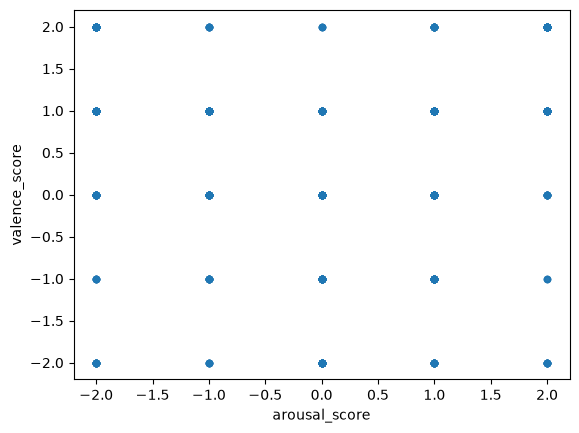

                            OLS Regression Results                            
Dep. Variable:          valence_score   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                   0.09689
Date:                Thu, 08 Oct 2026   Prob (F-statistic):              0.756
Time:                        11:01:50   Log-Likelihood:                -3887.2
No. Observations:                2373   AIC:                             7778.
Df Residuals:                    2371   BIC:                             7790.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.2742      0.026     10.725

In [5]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Fitting the line
df.plot.scatter(x="arousal_score", y="valence_score", alpha=0.2)
plt.show()

X = sm.add_constant(df["arousal_score"])  # adds the intercept
model = sm.OLS(df["valence_score"], X).fit()
print(model.summary())
# Summary will be compared against a closed-form version in the next cell to verify our equations

In [6]:
# Setting up x and y to correlate to their respective dataframes
x, y = df["arousal_score"], df["valence_score"]

# equation for b1
b1 = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean())**2).sum()

# equation for b0
b0 = y.mean() - b1 * x.mean()
print(b0, b1)

0.2742455222640473 0.005982657428212939


While the values do match, I'm realizing I should have already tested my dataset for problems seen in this graph. Looking for help or ideas.